# Titanic Survival Predictive Model

This notebook builds and evaluates a Logistic Regression model that predicts whether a Titanic passenger survived. It uses the supplied `Titanic-Dataset.csv` file and follows a leakage-safe scikit-learn pipeline workflow.

In [1]:
from pathlib import Path

DATASET_FILENAME = 'Titanic-Dataset.csv'
RANDOM_STATE = 42
NOTEBOOK_DIR = Path.cwd()

print(f'Notebook directory: {NOTEBOOK_DIR}')

Notebook directory: /Users/mdtariqueatique/Downloads/VIVA


## Built-in validation check: dataset path

The assertion below verifies that a missing dataset produces a clear and helpful error message.

In [2]:
def resolve_dataset_path(notebook_dir: Path) -> Path:
    """Return the local Titanic CSV path or raise a clear error."""
    dataset_path = notebook_dir / DATASET_FILENAME
    if not dataset_path.is_file():
        raise FileNotFoundError(
            f'Dataset file not found: {dataset_path}. '
            f'Place {DATASET_FILENAME} beside this notebook.'
        )
    return dataset_path

In [3]:
missing_directory = NOTEBOOK_DIR / '_missing_dataset_directory_'
try:
    resolve_dataset_path(missing_directory)
except FileNotFoundError as error:
    assert DATASET_FILENAME in str(error)
else:
    raise AssertionError('A missing dataset directory must raise FileNotFoundError.')

print('PASS: missing dataset paths produce a clear FileNotFoundError.')

PASS: missing dataset paths produce a clear FileNotFoundError.


## Built-in validation checks: schema and feature engineering

These assertions verify that missing required columns are identified clearly and that the derived family features are calculated correctly.

In [4]:
import pandas as pd

REQUIRED_COLUMNS = {
    'PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age',
    'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked',
}

def validate_dataset(data: pd.DataFrame) -> None:
    """Check the Titanic schema and binary target before modeling."""
    missing_columns = sorted(REQUIRED_COLUMNS - set(data.columns))
    if missing_columns:
        raise ValueError(
            'Dataset is missing required column(s): ' + ', '.join(missing_columns)
        )

    if data['Survived'].isna().any():
        raise ValueError('Survived must not contain missing values.')

    target_values = set(data['Survived'].unique())
    if not target_values.issubset({0, 1}):
        raise ValueError('Survived must contain only binary values 0 and 1.')

def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Return a copy with interpretable family-based features."""
    validate_dataset(data)
    prepared = data.copy()
    prepared['FamilySize'] = prepared['SibSp'] + prepared['Parch'] + 1
    prepared['IsAlone'] = (prepared['FamilySize'] == 1).astype(int)
    return prepared

In [5]:
sample_passengers = pd.DataFrame({
    'PassengerId': [1, 2],
    'Survived': [0, 1],
    'Pclass': [3, 1],
    'Name': ['Passenger One', 'Passenger Two'],
    'Sex': ['male', 'female'],
    'Age': [22.0, 38.0],
    'SibSp': [0, 1],
    'Parch': [0, 0],
    'Ticket': ['A/5 21171', 'PC 17599'],
    'Fare': [7.25, 71.2833],
    'Cabin': [None, 'C85'],
    'Embarked': ['S', 'C'],
})

try:
    validate_dataset(sample_passengers.drop(columns='Sex'))
except ValueError as error:
    assert 'Sex' in str(error)
else:
    raise AssertionError('Missing required columns must raise ValueError.')

engineered_sample = engineer_features(sample_passengers)
assert engineered_sample['FamilySize'].tolist() == [1, 2]
assert engineered_sample['IsAlone'].tolist() == [1, 0]
assert 'FamilySize' not in sample_passengers.columns

print('PASS: schema validation and family features behave as expected.')

PASS: schema validation and family features behave as expected.


## 1. Load and explore the dataset

The dataset is loaded from the same folder as this notebook. The validation and feature-engineering checks above run before any exploration or modeling.

In [6]:
dataset_path = resolve_dataset_path(NOTEBOOK_DIR)
raw_data = pd.read_csv(dataset_path)
validate_dataset(raw_data)
titanic_data = engineer_features(raw_data)

print(f'Dataset shape: {titanic_data.shape[0]} rows x {titanic_data.shape[1]} columns')
display(titanic_data.head())

Dataset shape: 891 rows x 14 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1


In [7]:
dataset_overview = pd.DataFrame({
    'Data type': titanic_data.dtypes.astype(str),
    'Non-null values': titanic_data.notna().sum(),
    'Missing values': titanic_data.isna().sum(),
    'Missing percentage': (titanic_data.isna().mean() * 100).round(2),
})

print('Dataset structure and missing values')
display(dataset_overview)

survival_counts = titanic_data['Survived'].value_counts().sort_index()
survival_summary = pd.DataFrame({
    'Count': survival_counts.to_numpy(),
    'Percentage': (survival_counts / len(titanic_data) * 100).round(2).to_numpy(),
}, index=['Did not survive (0)', 'Survived (1)'])
assert survival_summary['Count'].tolist() == [549, 342], 'Target-distribution counts must align with their labels.'
print('Target distribution')
display(survival_summary)

Dataset structure and missing values


,Data type,Non-null values,Missing values,Missing percentage
PassengerId,int64,891,0,0.00
Survived,int64,891,0,0.00
Pclass,int64,891,0,0.00
Name,object,891,0,0.00
Sex,object,891,0,0.00
Age,float64,714,177,19.87
SibSp,int64,891,0,0.00
Parch,int64,891,0,0.00
Ticket,object,891,0,0.00
Fare,float64,891,0,0.00


Target distribution


,Count,Percentage
Did not survive (0),549,61.62
Survived (1),342,38.38


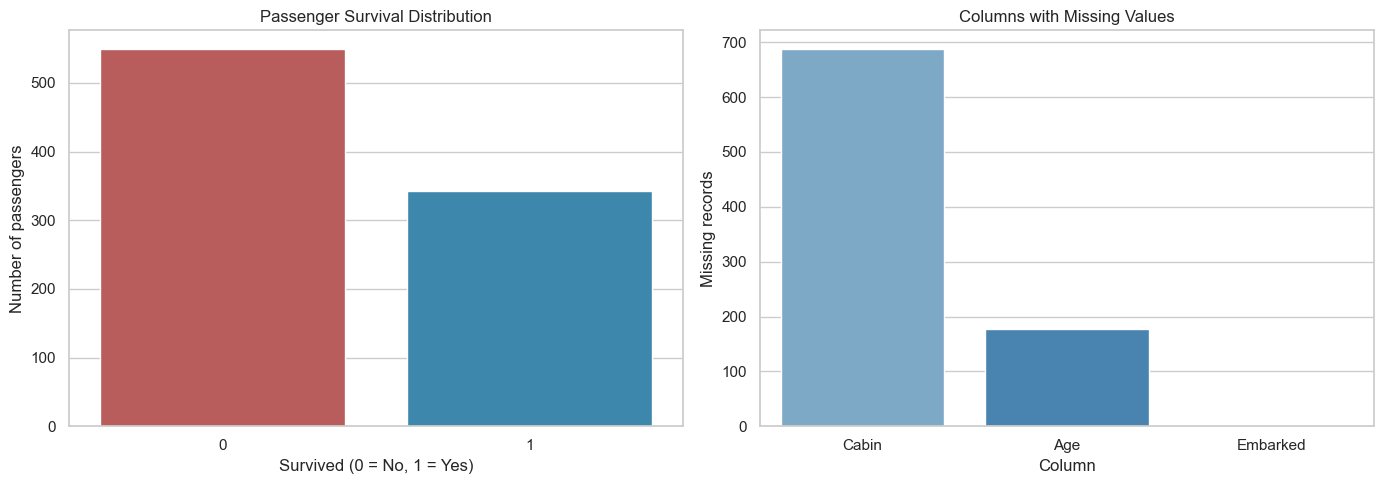

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=titanic_data, x='Survived', hue='Survived', legend=False, palette=['#c94c4c', '#2b8cbe'], ax=axes[0])
axes[0].set_title('Passenger Survival Distribution')
axes[0].set_xlabel('Survived (0 = No, 1 = Yes)')
axes[0].set_ylabel('Number of passengers')

missing_counts = titanic_data.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
sns.barplot(x=missing_counts.index, y=missing_counts.values, hue=missing_counts.index, legend=False, palette='Blues_d', ax=axes[1])
axes[1].set_title('Columns with Missing Values')
axes[1].set_xlabel('Column')
axes[1].set_ylabel('Missing records')

plt.tight_layout()
plt.show()

### Preprocessing decisions

Age is missing for some passengers and will be median-imputed. Embarked has very few missing values and will be imputed with its most common value. Cabin, Name, Ticket, and PassengerId are excluded from the simple model because they are identifier-like or high-cardinality text fields. The model uses Age, SibSp, Parch, Fare, Pclass, Sex, Embarked, FamilySize, and IsAlone.

## Built-in validation check: leakage-safe model pipeline

This test requires a pipeline with separate numeric and categorical transformations and checks that a future unseen port category does not cause prediction to fail.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FEATURES = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
CATEGORICAL_FEATURES = ['Pclass', 'Sex', 'Embarked']
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def build_model_pipeline() -> Pipeline:
    """Build a leakage-safe preprocessing and Logistic Regression pipeline."""
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preprocessor = ColumnTransformer(transformers=[
        ('numeric', numeric_transformer, NUMERIC_FEATURES),
        ('categorical', categorical_transformer, CATEGORICAL_FEATURES),
    ])
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

test_numeric_features = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
test_categorical_features = ['Pclass', 'Sex', 'Embarked']
test_feature_columns = test_numeric_features + test_categorical_features
X_for_test = titanic_data[test_feature_columns]
y_for_test = titanic_data['Survived']

pipeline_under_test = build_model_pipeline()
assert isinstance(pipeline_under_test.named_steps['preprocessor'], ColumnTransformer)
assert 'classifier' in pipeline_under_test.named_steps

X_train_check, X_test_check, y_train_check, _ = train_test_split(
    X_for_test, y_for_test, test_size=0.20, random_state=RANDOM_STATE, stratify=y_for_test
)
pipeline_under_test.fit(X_train_check, y_train_check)
unseen_category_row = X_test_check.iloc[[0]].copy()
unseen_category_row.loc[:, 'Embarked'] = 'Z'
assert pipeline_under_test.predict(unseen_category_row).shape == (1,)

print('PASS: pipeline supports required transforms and unseen categories.')

PASS: pipeline supports required transforms and unseen categories.


## 2. Split the data and train the model

The target is separated before training. An 80/20 stratified split preserves the original survival balance in both subsets. Imputation, scaling, and encoding are fitted only on the training set inside the pipeline.

In [11]:
assert 'Survived' not in FEATURE_COLUMNS, 'The target must never be a model input.'

X = titanic_data[FEATURE_COLUMNS].copy()
y = titanic_data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

model_pipeline = build_model_pipeline()
model_pipeline.fit(X_train, y_train)

split_summary = pd.DataFrame({
    'Rows': [len(X_train), len(X_test)],
    'Survival rate (%)': [(y_train.mean() * 100).round(2), (y_test.mean() * 100).round(2)],
}, index=['Training set', 'Test set'])
display(split_summary)
print('PASS: target leakage check and stratified model training completed.')

,Rows,Survival rate (%)
Training set,712,38.34
Test set,179,38.55


PASS: target leakage check and stratified model training completed.


## Built-in validation check: evaluation integrity

This test defines the required classification metrics and verifies that the final model returns valid binary predictions and probabilities.

In [12]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

def evaluate_model(
    fitted_pipeline: Pipeline,
    features: pd.DataFrame,
    target: pd.Series,
    training_target: pd.Series,
) -> tuple[pd.Series, np.ndarray, np.ndarray]:
    """Evaluate a fitted binary classifier on an untouched holdout set."""
    predictions = fitted_pipeline.predict(features)
    probabilities = fitted_pipeline.predict_proba(features)[:, 1]
    majority_class = training_target.mode().iloc[0]
    majority_predictions = np.full(shape=len(target), fill_value=majority_class)
    metrics = pd.Series({
        'Majority baseline accuracy': accuracy_score(target, majority_predictions),
        'Accuracy': accuracy_score(target, predictions),
        'Precision': precision_score(target, predictions, zero_division=0),
        'Recall': recall_score(target, predictions, zero_division=0),
        'F1 score': f1_score(target, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(target, probabilities),
    })
    return metrics, predictions, probabilities

In [13]:
import numpy as np

metrics_under_test, predictions_under_test, probabilities_under_test = evaluate_model(
    model_pipeline, X_test, y_test, y_train
)
expected_metric_names = {
    'Majority baseline accuracy', 'Accuracy', 'Precision', 'Recall', 'F1 score', 'ROC-AUC'
}
assert expected_metric_names.issubset(metrics_under_test.index)
assert set(predictions_under_test).issubset({0, 1})
assert len(probabilities_under_test) == len(y_test)
assert np.all((probabilities_under_test >= 0) & (probabilities_under_test <= 1))

print('PASS: evaluation returns valid classification metrics and probabilities.')

PASS: evaluation returns valid classification metrics and probabilities.


## 3. Evaluate model performance

The following measures are appropriate for binary classification. Accuracy is compared with a simple majority-class baseline, while precision, recall, F1 score, and ROC-AUC describe different aspects of the classifier's performance. MSE and R2 are regression metrics, so they are not appropriate for this task.

In [14]:
metrics, y_pred, y_prob = evaluate_model(model_pipeline, X_test, y_test, y_train)
performance_table = (metrics.mul(100).round(2).rename('Percentage')).to_frame()
display(performance_table)

improvement = (metrics['Accuracy'] - metrics['Majority baseline accuracy']) * 100
print(f'Accuracy improvement over the majority baseline: {improvement:.2f} percentage points')

,Percentage
Majority baseline accuracy,61.45
Accuracy,81.56
Precision,81.03
Recall,68.12
F1 score,74.02
ROC-AUC,85.06


Accuracy improvement over the majority baseline: 20.11 percentage points


Classification report
                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.68      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.82      0.82      0.81       179



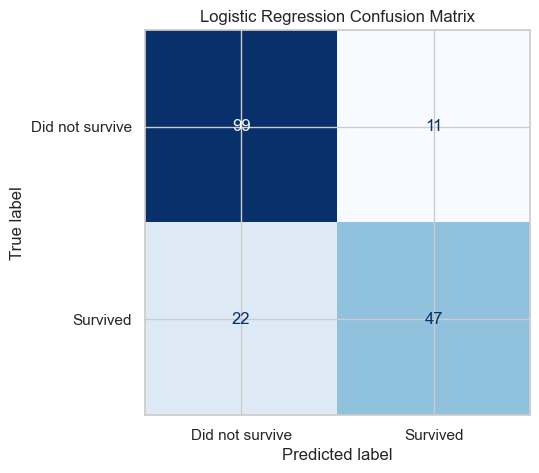

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print('Classification report')
print(classification_report(y_test, y_pred, target_names=['Did not survive', 'Survived'], zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Did not survive', 'Survived'],
    cmap='Blues', colorbar=False, ax=ax,
)
ax.set_title('Logistic Regression Confusion Matrix')
plt.show()

### Cross-validation on the training data

Cross-validation checks whether performance is reasonably stable across different subsets of the training data. The untouched test set above remains reserved for the final evaluation.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(
    build_model_pipeline(), X_train, y_train,
    cv=cross_validator, scoring='accuracy'
)
cv_summary = pd.DataFrame({
    'Fold': range(1, len(cv_scores) + 1),
    'Accuracy (%)': (cv_scores * 100).round(2),
})
display(cv_summary)
print(f'Mean CV accuracy: {cv_scores.mean() * 100:.2f}%')
print(f'CV standard deviation: {cv_scores.std() * 100:.2f}%')

,Fold,Accuracy (%)
0,1,80.42
1,2,78.32
2,3,80.28
3,4,77.46
4,5,81.69


Mean CV accuracy: 79.64%
CV standard deviation: 1.53%


## 4. Interpret the model

Logistic Regression coefficients show the direction of each transformed feature. A positive coefficient increases the model's estimated chance of survival; a negative coefficient decreases it. Numerical fields are standardized while categorical fields are one-hot indicators, so coefficient magnitudes are not a universal feature-importance ranking. FamilySize also overlaps with SibSp and Parch, so correlated features can share effects. These are associations in this dataset, not proof of causation.

In [17]:
fitted_preprocessor = model_pipeline.named_steps['preprocessor']
fitted_classifier = model_pipeline.named_steps['classifier']
coefficient_table = pd.DataFrame({
    'Feature': fitted_preprocessor.get_feature_names_out(),
    'Coefficient': fitted_classifier.coef_.ravel(),
}).sort_values('Coefficient')

print('Strongest negative associations with survival')
display(coefficient_table.head(5).reset_index(drop=True))
print('Strongest positive associations with survival')
display(coefficient_table.tail(5).sort_values('Coefficient', ascending=False).reset_index(drop=True))

Strongest negative associations with survival


,Feature,Coefficient
0,categorical__Sex_male,-1.215625
1,categorical__Pclass_3,-1.010855
2,numeric__Age,-0.475758
3,numeric__IsAlone,-0.306440
4,categorical__Embarked_S,-0.305060


Strongest positive associations with survival


,Feature,Coefficient
0,categorical__Sex_female,1.320469
1,categorical__Pclass_1,1.016059
2,categorical__Embarked_Q,0.376037
3,numeric__Fare,0.110699
4,categorical__Pclass_2,0.099640


## 5. Observations and conclusion

The notebook compares the final model with a majority-class baseline, so its value is not judged by accuracy alone. The model is intentionally simple and interpretable, but its results are limited by the small historical dataset, missing information, and the fact that the passenger sample is not representative of modern survival settings.

In [18]:
top_positive = coefficient_table.iloc[-1]
top_negative = coefficient_table.iloc[0]

print('Viva-ready conclusion')
print(
    f'The Logistic Regression model achieved {metrics["Accuracy"] * 100:.2f}% accuracy on the unseen test set, '
    f'compared with a {metrics["Majority baseline accuracy"] * 100:.2f}% majority-class baseline. '
    f'Its ROC-AUC was {metrics["ROC-AUC"]:.3f}. '
    f'The strongest positive coefficient was {top_positive["Feature"]}, while the strongest negative coefficient was {top_negative["Feature"]}. '
    'The pipeline handles missing values and categorical variables safely, but the result should be interpreted as a simple educational model rather than a production decision system.'
)

Viva-ready conclusion
The Logistic Regression model achieved 81.56% accuracy on the unseen test set, compared with a 61.45% majority-class baseline. Its ROC-AUC was 0.851. The strongest positive coefficient was categorical__Sex_female, while the strongest negative coefficient was categorical__Sex_male. The pipeline handles missing values and categorical variables safely, but the result should be interpreted as a simple educational model rather than a production decision system.
